# S04 — Perception visuelle : choisir le bon graphique

Un même tableau de chiffres peut conduire à des conclusions très différentes selon la façon dont on le dessine.
Aujourd'hui, nous allons :

1. mesurer ce que l'œil lit bien (et mal) ;
2. diagnostiquer trois graphiques ratés construits sur nos données NYC Taxi ;
3. les refaire correctement ;
4. apprendre à choisir le graphique à partir de la question posée.

Prérequis : les tables `gold_trajets_horaires` et `gold_zones` existent dans PostgreSQL (séance S02).

In [1]:
import sys; sys.path.append("/home/jovyan/work")
from commun.donnees import lire

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

horaires = lire("gold_trajets_horaires")
zones = lire("gold_zones")
horaires["heure_pickup"] = pd.to_datetime(horaires["heure_pickup"])
# Fuseau horaire : PostgreSQL renvoie les horaires en UTC -> on repasse à l'heure de New York
if horaires["heure_pickup"].dt.tz is not None:
    horaires["heure_pickup"] = horaires["heure_pickup"].dt.tz_convert("America/New_York").dt.tz_localize(None)
print("Type des horaires :", horaires["heure_pickup"].dtype)
horaires["heure"] = horaires["heure_pickup"].dt.hour
arr = (horaires[~horaires["arrondissement"].isin(["Unknown", "N/A"])]
       .groupby("arrondissement", as_index=False)
       .agg(courses=("courses", "sum"), revenu=("revenu", "sum")))
arr["prix_moyen"] = arr["revenu"] / arr["courses"]
arr

Type des horaires : datetime64[ns]


,arrondissement,courses,revenu,prix_moyen
0,Bronx,5895,233837.38,39.667070
1,Brooklyn,23951,769073.75,32.110298
2,EWR,74,6663.60,90.048649
3,Manhattan,2532822,57826450.49,22.830839
4,Queens,244700,18837645.81,76.982615
5,Staten Island,71,1854.34,26.117465


## 1. Ce que l'œil lit bien

Cleveland et McGill (1984) ont mesuré la précision avec laquelle on compare des quantités selon leur encodage visuel.
Du plus précis au moins précis :

1. **position sur une échelle commune** (barres alignées, points) ;
2. position sur des échelles non alignées ;
3. **longueur** ;
4. angle, pente ;
5. **aire** ;
6. volume, saturation et teinte de couleur.

Testez-le : sans lire les nombres, classez les cinq valeurs ci-dessous sur le camembert, puis sur les barres.

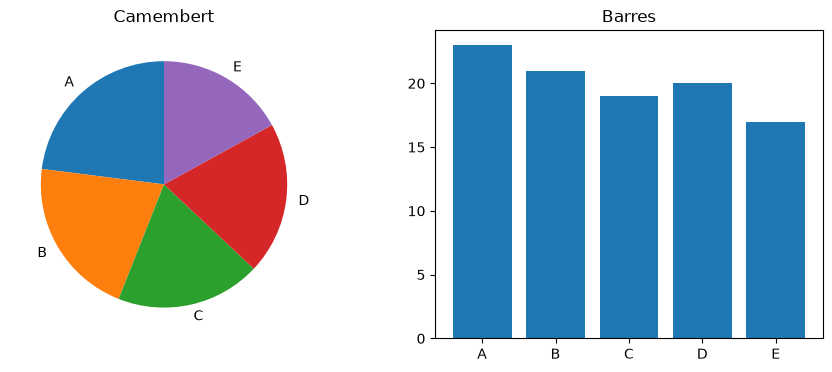

In [2]:
valeurs = pd.Series([23, 21, 19, 20, 17], index=list("ABCDE"))
fig, (g, d) = plt.subplots(1, 2, figsize=(11, 4))
g.pie(valeurs, labels=valeurs.index, startangle=90); g.set_title("Camembert")
d.bar(valeurs.index, valeurs); d.set_title("Barres")
plt.show()

Sur le camembert, l'ordre est presque impossible à lire. Sur les barres, il saute aux yeux.
C'est la différence entre un angle et une position sur une échelle commune.

## 2. Atelier : trois graphiques ratés

Pour chacun des trois graphiques :

- écrivez **la question** à laquelle il devrait répondre ;
- listez **tout ce qui ne va pas** (type de graphique, axes, couleurs, titre, unités…) ;
- **refaites-le** dans la cellule prévue, puis justifiez chaque choix en une phrase.

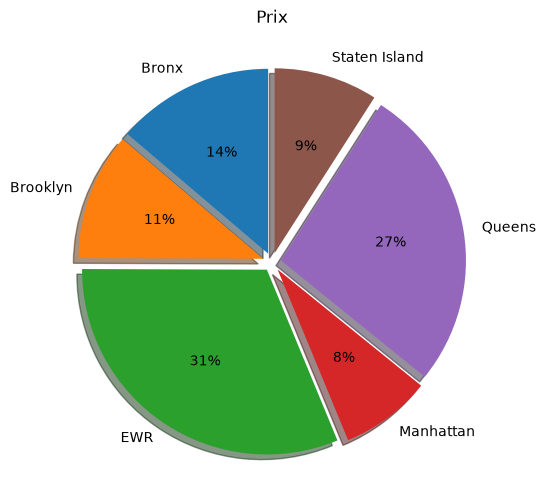

In [3]:
# Graphique A
plt.figure(figsize=(6, 6))
plt.pie(arr["prix_moyen"], labels=arr["arrondissement"], autopct="%1.0f%%",
        explode=[0.05] * len(arr), shadow=True, startangle=90)
plt.title("Prix")
plt.show()

**Graphique A**

- **Question visée :** dans quel arrondissement une course coûte-t-elle le plus cher en moyenne ?
- **Ce qui ne va pas :**
  - un camembert montre les parts d'un tout ; or une somme de prix moyens n'a aucun sens → les « % » affichés sont faux par construction ;
  - comparer des angles est imprécis (Cleveland & McGill), surtout avec 6 parts de tailles proches ;
  - effets décoratifs (explode, ombre) qui n'apportent aucune information ;
  - pas d'unité (dollars), pas de valeurs lisibles, catégories non triées ;
  - couleurs arbitraires sans signification ;
  - titre « Prix » : un sujet, pas une conclusion.
- **Attention :** EWR (aéroport de Newark) et Staten Island ne comptent qu'environ 70 courses chacun : leur moyenne est fragile.
- **Refonte :** barres horizontales triées (position sur échelle commune), axe qui part de 0, une seule couleur
  (la couleur ne code rien), valeur en dollars écrite au bout de chaque barre, titre qui énonce le résultat.

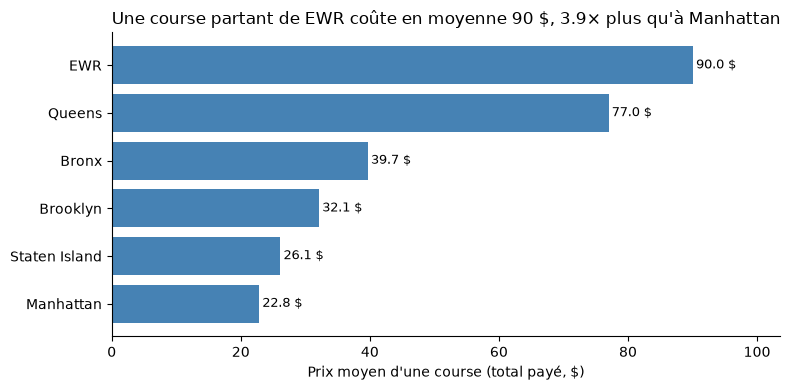

In [4]:
# Votre version du graphique A
a = arr.sort_values("prix_moyen")                     # tri : l'ordre se lit immédiatement
fig, ax = plt.subplots(figsize=(8, 4))
ax.barh(a["arrondissement"], a["prix_moyen"], color="steelblue")   # une seule couleur : elle ne code rien
for y, v in enumerate(a["prix_moyen"]):
    ax.text(v + 0.5, y, f"{v:.1f} $", va="center", fontsize=9)    # valeurs lisibles sans légende
ax.set_xlim(0, a["prix_moyen"].max() * 1.15)            # barres : axe à zéro
ax.set_xlabel("Prix moyen d'une course (total payé, $)")
haut, bas = a.iloc[-1], a.iloc[0]
ax.set_title(f"Une course partant de {haut['arrondissement']} coûte en moyenne {haut['prix_moyen']:.0f} $, "
             f"{haut['prix_moyen'] / bas['prix_moyen']:.1f}× plus qu'à {bas['arrondissement']}", loc="left")
ax.spines[["top", "right"]].set_visible(False)
plt.tight_layout(); plt.show()

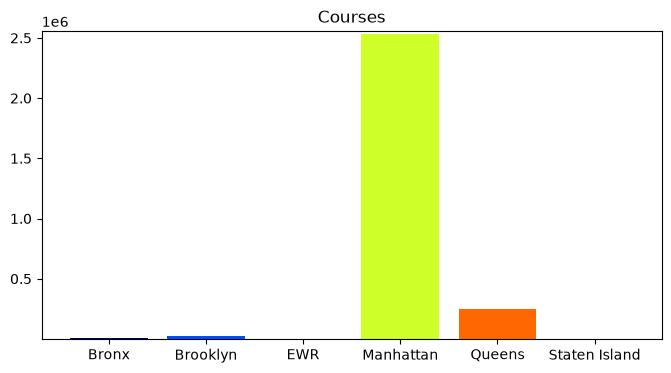

In [5]:
# Graphique B
couleurs = plt.cm.jet(np.linspace(0, 1, len(arr)))
plt.figure(figsize=(8, 4))
plt.bar(arr["arrondissement"], arr["courses"], color=couleurs)
plt.ylim(arr["courses"].min() * 0.95, arr["courses"].max() * 1.01)
plt.title("Courses")
plt.show()

**Graphique B**

- **Question visée :** quels arrondissements génèrent le plus de courses ?
- **Ce qui ne va pas :**
  - **l'axe Y ne commence pas à zéro** (`ylim` à 95 % du minimum) : les longueurs de barres ne sont plus proportionnelles,
    le plus petit arrondissement paraît presque nul et les écarts sont faussés ;
  - palette `jet` (arc-en-ciel) : la couleur ne code rien ici et crée des différences qui n'existent pas ; illisible pour une partie des daltoniens ;
  - barres non triées, étiquettes verticales qui risquent de se chevaucher ;
  - pas d'unité ni de période (« courses » sur le mois entier) ;
  - titre « Courses » : un sujet, pas une conclusion.
- **Refonte :** barres horizontales triées, axe à 0, une couleur neutre + une couleur d'accent pour la barre qui porte le message,
  part du total (%) écrite à côté de chaque barre, titre qui donne la conclusion.

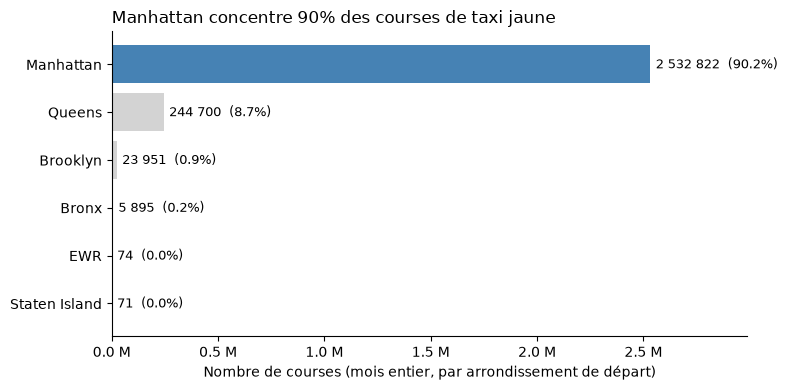

In [6]:
# Votre version du graphique B
b = arr.sort_values("courses")
part = b["courses"] / b["courses"].sum()
couleurs_b = ["lightgray"] * (len(b) - 1) + ["steelblue"]      # accent = le message du titre
fig, ax = plt.subplots(figsize=(8, 4))
ax.barh(b["arrondissement"], b["courses"], color=couleurs_b)
ax.set_xlim(0, b["courses"].max() * 1.18)                       # barres : axe à zéro
for y, (v, p) in enumerate(zip(b["courses"], part)):
    ax.text(v + b["courses"].max() * 0.01, y, f"{v:,.0f}  ({p:.1%})".replace(",", " "), va="center", fontsize=9)
ax.xaxis.set_major_formatter(lambda x, _: f"{x / 1e6:.1f} M" if b["courses"].max() >= 1e6 else f"{x:,.0f}")
ax.set_xlabel("Nombre de courses (mois entier, par arrondissement de départ)")
ax.set_title(f"{b.iloc[-1]['arrondissement']} concentre {part.iloc[-1]:.0%} des courses de taxi jaune", loc="left")
ax.spines[["top", "right"]].set_visible(False)
plt.tight_layout(); plt.show()

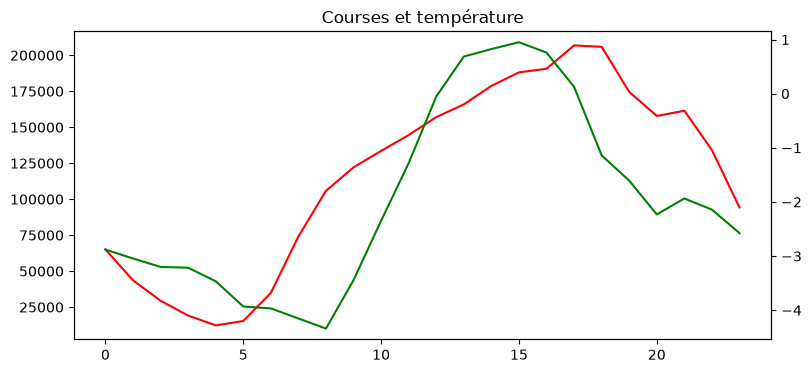

In [7]:
# Graphique C
par_heure = horaires.groupby("heure").agg(courses=("courses", "sum"), temperature=("temperature_c", "mean"))
fig, ax1 = plt.subplots(figsize=(9, 4))
ax1.plot(par_heure.index, par_heure["courses"], color="red")
ax2 = ax1.twinx()
ax2.plot(par_heure.index, par_heure["temperature"], color="green")
ax2.set_ylim(par_heure["temperature"].min() - 0.2, par_heure["temperature"].max() + 0.2)
plt.title("Courses et température")
plt.show()

**Graphique C**

- **Question visée :** la demande de taxis suit-elle la température au fil de la journée ?
- **Ce qui ne va pas :**
  - **double axe Y** : les deux échelles sont choisies arbitrairement, on peut faire « coïncider » ou « diverger » les courbes à volonté ;
  - l'axe de température est **resserré à ±0,2 °C** : une variation de quelques degrés paraît énorme ;
  - rouge / vert : couleurs sans sens et indiscernables pour les daltoniens (deutéranopie) ;
  - aucun libellé d'axe, aucune unité, pas de légende : impossible de savoir quelle courbe est laquelle ;
  - titre « Courses et température » : un sujet, pas une conclusion ;
  - piège d'interprétation : sur une journée type, les deux grandeurs varient avec l'heure → une ressemblance ne prouve pas un lien.
- **Refonte :** deux panneaux superposés qui partagent l'axe des heures (*small multiples*) au lieu d'un double axe,
  chaque panneau avec son unité, axe des courses à 0, température sur une échelle honnête,
  couleurs neutres et distinguables, titre qui énonce ce qu'on voit (et ce qu'on ne peut pas conclure).

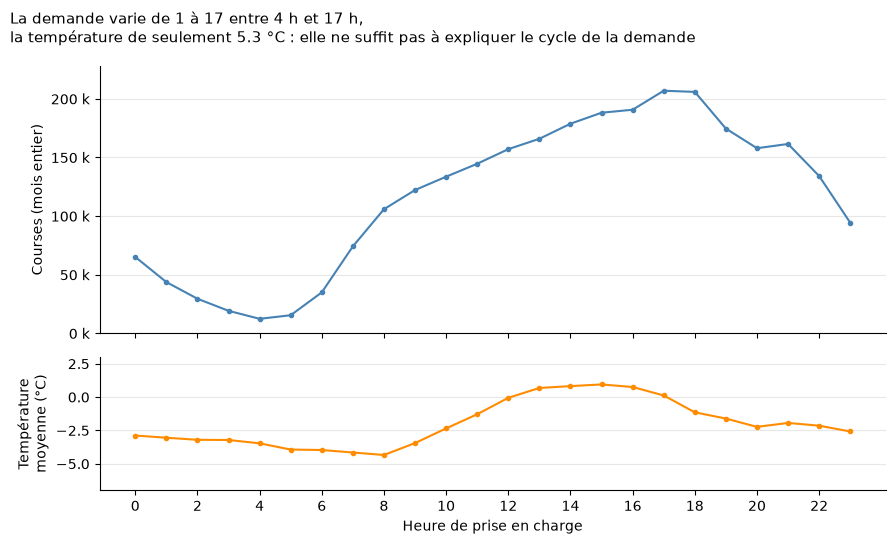

In [8]:
# Votre version du graphique C
fig, (h1, h2) = plt.subplots(2, 1, figsize=(9, 5.5), sharex=True, gridspec_kw={"height_ratios": [2, 1]})

h1.plot(par_heure.index, par_heure["courses"], color="steelblue", marker="o", ms=3)
h1.set_ylim(0, par_heure["courses"].max() * 1.1)
h1.set_ylabel("Courses (mois entier)")
h1.yaxis.set_major_formatter(lambda x, _: f"{x / 1e3:,.0f} k".replace(",", " "))

h2.plot(par_heure.index, par_heure["temperature"], color="darkorange", marker="o", ms=3)
t_min, t_max = par_heure["temperature"].min(), par_heure["temperature"].max()
h2.set_ylim(np.floor(t_min) - 2, np.ceil(t_max) + 2)          # marge de quelques degrés, pas ±0,2 °C
h2.set_ylabel("Température\nmoyenne (°C)")
h2.set_xlabel("Heure de prise en charge")
h2.set_xticks(range(0, 24, 2))

for ax in (h1, h2):
    ax.spines[["top", "right"]].set_visible(False); ax.grid(axis="y", alpha=0.3)

pic, creux = par_heure["courses"].idxmax(), par_heure["courses"].idxmin()
ratio = par_heure.loc[pic, "courses"] / par_heure.loc[creux, "courses"]
fig.suptitle(f"La demande varie de 1 à {ratio:.0f} entre {creux} h et {pic} h, "
             f"\nla température de seulement {t_max - t_min:.1f} °C : elle ne suffit pas à expliquer le cycle de la demande",
             x=0.01, ha="left", fontsize=11)
plt.tight_layout(); plt.show()

## 3. Choisir le graphique à partir de la question

| La question porte sur… | Graphique adapté | À éviter |
|---|---|---|
| une **comparaison** entre catégories | barres horizontales triées, points | camembert à plus de 3 parts, 3D |
| une **évolution** dans le temps | courbe, aires | barres très nombreuses, axe non chronologique |
| une **répartition** d'une variable | histogramme, boîte à moustaches | moyenne seule |
| une **relation** entre deux variables | nuage de points (avec agrégation si gros volume) | double axe |
| une **part d'un tout** (peu de parts) | barre empilée à 100 %, camembert à 2–3 parts | camembert à 8 parts |
| une **géographie** | carte choroplèthe (valeurs normalisées) | carte de valeurs brutes non rapportées |

**Exercice :** pour chacune des questions suivantes, choisissez un graphique, construisez-le et donnez-lui un titre qui énonce la conclusion
(pas seulement le sujet).

1. À quelle heure la demande est-elle la plus forte ?
2. Quelles sont les 10 zones de départ où le prix moyen est le plus élevé ?
3. La distance moyenne des courses varie-t-elle selon l'heure ?

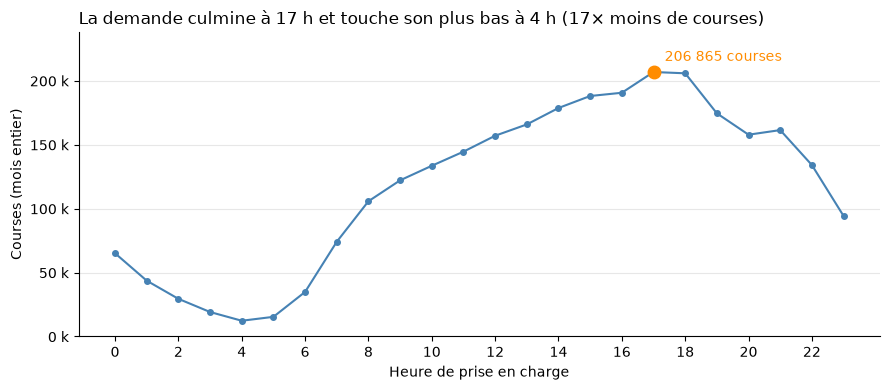

In [9]:
# Question 1 — À quelle heure la demande est-elle la plus forte ?
# Évolution sur la journée → courbe ; le pic est mis en évidence par une couleur d'accent.
q1 = horaires.groupby("heure")["courses"].sum()
pic = q1.idxmax()
fig, ax = plt.subplots(figsize=(9, 4))
ax.plot(q1.index, q1.values, color="steelblue", marker="o", ms=4)
ax.plot(pic, q1[pic], "o", color="darkorange", ms=9)
ax.annotate(f"{q1[pic]:,.0f} courses".replace(",", " "), (pic, q1[pic]),
            xytext=(8, 8), textcoords="offset points", color="darkorange")
ax.set_ylim(0, q1.max() * 1.15)
ax.set_xticks(range(0, 24, 2))
ax.set_xlabel("Heure de prise en charge")
ax.set_ylabel("Courses (mois entier)")
ax.yaxis.set_major_formatter(lambda x, _: f"{x / 1e3:,.0f} k".replace(",", " "))
ax.set_title(f"La demande culmine à {pic} h et touche son plus bas à {q1.idxmin()} h "
             f"({q1[pic] / q1.min():.0f}× moins de courses)", loc="left")
ax.spines[["top", "right"]].set_visible(False); ax.grid(axis="y", alpha=0.3)
plt.tight_layout(); plt.show()

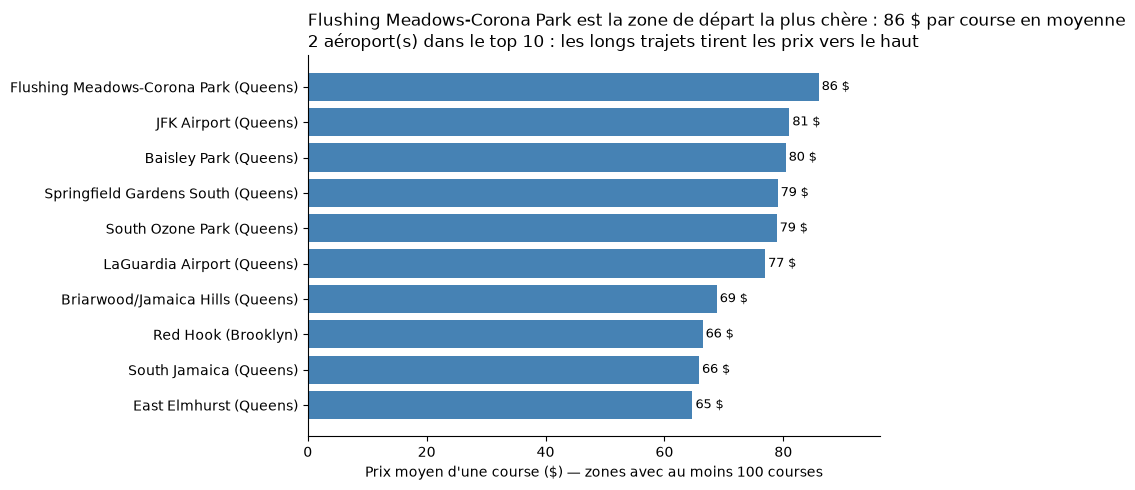

In [10]:
# Question 2 — Les 10 zones de départ où le prix moyen est le plus élevé
# Comparaison entre catégories → barres horizontales triées, axe à 0.
# On écarte les zones inconnues et celles avec trop peu de courses (moyenne instable).
SEUIL = 100
z = zones[zones["zone"].notna() & ~zones["zone"].isin(["Unknown", "N/A", "Outside of NYC"])
          & (zones["courses"] >= SEUIL)]
top = z.nlargest(10, "prix_moyen").sort_values("prix_moyen")
etiq = top["zone"] + " (" + top["arrondissement"] + ")"
fig, ax = plt.subplots(figsize=(9, 5))
ax.barh(etiq, top["prix_moyen"], color="steelblue")
for y, v in enumerate(top["prix_moyen"]):
    ax.text(v + 0.5, y, f"{v:.0f} $", va="center", fontsize=9)
ax.set_xlim(0, top["prix_moyen"].max() * 1.12)
ax.set_xlabel(f"Prix moyen d'une course ($) — zones avec au moins {SEUIL} courses")
n_aero = top["zone"].str.contains("Airport", case=False).sum()
premier = top.iloc[-1]
titre = f"{premier['zone']} est la zone de départ la plus chère : {premier['prix_moyen']:.0f} $ par course en moyenne"
if n_aero:
    titre += f"\n{n_aero} aéroport(s) dans le top 10 : les longs trajets tirent les prix vers le haut"
ax.set_title(titre, loc="left")
ax.spines[["top", "right"]].set_visible(False)
plt.tight_layout(); plt.show()

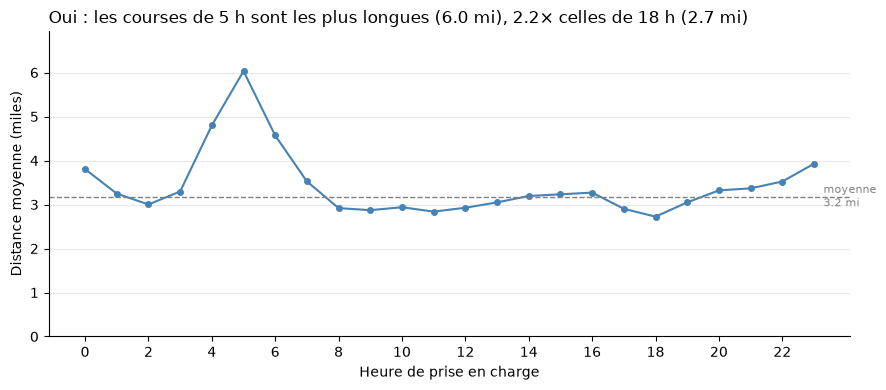

In [11]:
# Question 3 — La distance moyenne varie-t-elle selon l'heure ?
# Évolution sur la journée → courbe.
# Attention : distance_moyenne est déjà une moyenne par (heure, arrondissement) ;
# il faut la pondérer par le nombre de courses, pas faire une moyenne de moyennes.
d = (horaires.assign(dist_x_courses=horaires["distance_moyenne"] * horaires["courses"])
     .groupby("heure")[["dist_x_courses", "courses"]].sum())
q3 = d["dist_x_courses"] / d["courses"]
moy = (d["dist_x_courses"].sum() / d["courses"].sum())
fig, ax = plt.subplots(figsize=(9, 4))
ax.plot(q3.index, q3.values, color="steelblue", marker="o", ms=4)
ax.axhline(moy, color="gray", ls="--", lw=1)
ax.text(23.3, moy, f"moyenne\n{moy:.1f} mi", va="center", fontsize=8, color="gray")
ax.set_ylim(0, q3.max() * 1.15)
ax.set_xticks(range(0, 24, 2))
ax.set_xlabel("Heure de prise en charge")
ax.set_ylabel("Distance moyenne (miles)")
hmax, hmin = q3.idxmax(), q3.idxmin()
verdict = "Oui" if q3[hmax] / q3[hmin] >= 1.2 else "Peu"
ax.set_title(f"{verdict} : les courses de {hmax} h sont les plus longues ({q3[hmax]:.1f} mi), "
             f"{q3[hmax] / q3[hmin]:.1f}× celles de {hmin} h ({q3[hmin]:.1f} mi)", loc="left")
ax.spines[["top", "right"]].set_visible(False); ax.grid(axis="y", alpha=0.3)
plt.tight_layout(); plt.show()

## 4. La couleur

- **Séquentielle** (du clair au foncé) pour une quantité qui va de faible à fort : `viridis`, `Blues`.
- **Divergente** (deux teintes autour d'un centre) pour un écart à une référence : `RdBu`, `PuOr`.
- **Catégorielle** (teintes distinctes) pour des groupes sans ordre : `tab10`, `Set2`.
- À proscrire : `jet` et les arcs-en-ciel, qui créent des frontières qui n'existent pas dans les données
  et sont illisibles pour une partie des daltoniens.

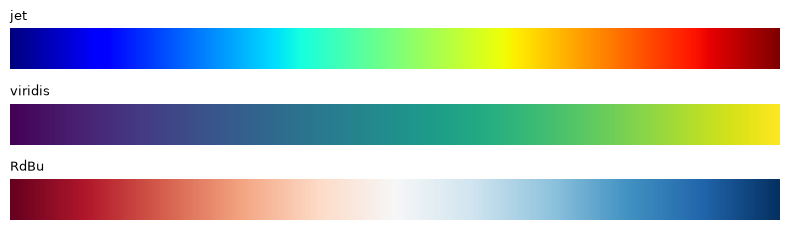

In [12]:
x = np.linspace(0, 1, 256).reshape(1, -1)
fig, axes = plt.subplots(3, 1, figsize=(8, 2.4))
for ax, nom in zip(axes, ["jet", "viridis", "RdBu"]):
    ax.imshow(x, aspect="auto", cmap=nom); ax.set_axis_off(); ax.set_title(nom, fontsize=9, loc="left")
plt.tight_layout(); plt.show()

## À retenir

- On part toujours de **la question**, jamais de l'outil.
- On privilégie la **position sur une échelle commune** ; on se méfie des angles, des aires et de la 3D.
- Un axe de barres commence à **zéro**.
- Le titre énonce **la conclusion** ; les axes ont des **unités**.
- La couleur a un **sens** (séquentielle, divergente, catégorielle) ou n'est pas utilisée.